# Base de Dados para Modelo de Recomendação - Aventura Teatros

## 1. Introdução

O Portal Aventura ainda não possui um mecanismo estruturado de recomendação de espetáculos. Na prática, isso limita a descoberta de novas experiências: o usuário acessa um espetáculo específico, mas não recebe sugestões relacionadas ao seu comportamento ou a perfis semelhantes.

Este notebook prepara a base de dados que será usada no modelo de recomendação. O foco é transformar registros transacionais em uma matriz usuário-item adequada para filtragem colaborativa, com ratings derivados de feedback implícito, tratamento de outliers, filtros de cold-start e revisão de balanceamento.

Ao final do pipeline, são gerados dois artefatos principais:

| Arquivo | Finalidade |
|---|---|
| `recomendacao_balanceado.csv` | Base final para treino e avaliação do recomendador |
| `itens_metadata.csv` | Metadados para interpretar os itens recomendados |


## 1.1 Estratégia de Feedback Implícito

A base disponível registra compras e interações transacionais dos usuários com os espetáculos. Como não há uma avaliação explícita confiável informada pelo usuário, a coluna `avaliacao` foi reconstruída a partir de sinais comportamentais reais.

### Sinais Utilizados

| Sinal | Origem | Interpretação |
|---|---|---|
| Recorrência usuário-evento | Quantidade de registros para o mesmo par `id_user` + `evento` | Repetição indica maior interesse ou engajamento com o espetáculo |
| Valor do ingresso | `valor_do_ingresso` | Maior disposição de pagamento sugere maior força de preferência |
| Antecedência da compra | Diferença entre `data_da_apresentacao` e `data_da_compra` | Compra antecipada indica planejamento e intenção mais forte |

### Fórmula do Score

Os sinais são normalizados em escala relativa e combinados em um `score_implicito` contínuo:

```python
score_implicito = (
    0.60 * score_recorrencia +
    0.25 * score_valor_ingresso +
    0.15 * score_antecedencia
)
```

A recorrência recebe o maior peso por representar o sinal mais diretamente ligado à relação usuário-item. O valor do ingresso entra como compromisso financeiro, e a antecedência atua como sinal complementar de intenção.

Após a consolidação por par usuário-item, o score contínuo é convertido em ratings ordinais de 1 a 5 por quintis. Dessa forma, o pipeline continua compatível com filtragem colaborativa baseada em ratings, mas os valores passam a refletir comportamento real observado na base.

### Enriquecimento por Produção

A coluna `tipo_producao` foi prevista para incorporar informações de uma base auxiliar de espetáculos, como produção externa, companhia ou corporativa. Quando essa coluna não está disponível no CSV versionado, o pipeline preenche o valor como `Nao informado` para manter o processamento estável e explícito.


## 2. Carregamento do Dataset

Nesta etapa, o dataset versionado em `src/dataset/recomendacao.csv` é carregado e padronizado. Também são recalculados os sinais de feedback implícito para garantir que o notebook seja reprodutível a partir da base atual.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Estilo de visualização
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.figsize'] = (10, 5)

# Carregamento
df = pd.read_csv('../dataset/recomendacao.csv')
df = df.rename(columns={'evento': 'nome_evento'})
if 'tipo_producao' not in df.columns:
    df['tipo_producao'] = 'Nao informado'

# Feedback implícito derivado de comportamento real
valor = pd.to_numeric(df['valor_do_ingresso'], errors='coerce').fillna(0).clip(lower=0)
compra = pd.to_datetime(df['data_da_compra'], errors='coerce', format='mixed')
apresentacao = pd.to_datetime(df['data_da_apresentacao'], errors='coerce', format='mixed')
antecedencia = (apresentacao - compra).dt.total_seconds().div(86400).clip(lower=0, upper=365).fillna(0)
interacoes = df.groupby(['id_user', 'nome_evento'])['nome_evento'].transform('size')

score_recorrencia = np.log1p(interacoes) / np.log1p(interacoes.max())
score_valor = valor.rank(pct=True, method='average')
score_antecedencia = antecedencia.rank(pct=True, method='average')

df['interacoes_user_item'] = interacoes.astype(int)
df['antecedencia_dias'] = antecedencia.round(2)
df['score_implicito'] = (
    0.60 * score_recorrencia +
    0.25 * score_valor +
    0.15 * score_antecedencia
).round(6)

# Rating inicial por linha, usado apenas para EDA. O rating final do modelo é recalculado após a agregação user-item.
df['avaliacao'] = pd.qcut(
    df['score_implicito'].rank(method='first'),
    q=5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

print('Dataset carregado com sucesso')
print(f'Registros carregados : {len(df):,}')
print(f'Colunas disponíveis : {df.shape[1]}')
print('Distribuição inicial do rating implícito:')
print(df['avaliacao'].value_counts().sort_index().to_string())
df.head()


Dataset carregado com sucesso
Registros carregados : 343,758
Colunas disponíveis : 13
Distribuição inicial do rating implícito:
avaliacao
1    68752
2    68751
3    68752
4    68751
5    68752


,id_user,nome_evento,teatro,data_da_apresentacao,data_da_compra,setor,valor_do_ingresso,categoria,interacoes_user_item,antecedencia_dias,score_implicito,avaliacao,tipo_producao
0,1,UM MALLANDRO NA QUARENTENA COM SERGIO MALLANDRO,TEATRO RIACHUELO RJ,6/26/21 20:00,5/20/21 5:03,PLATEIA VIP - 02 PESSOAS,120,Show Stand-Up,2,37.62,0.423159,4,Nao informado
1,1,UM MALLANDRO NA QUARENTENA COM SERGIO MALLANDRO,TEATRO RIACHUELO RJ,6/26/21 20:00,5/20/21 5:03,PLATEIA VIP - 02 PESSOAS,120,Show Stand-Up,2,37.62,0.423159,4,Nao informado
2,2,DOMINGUINHOS - ISSO AQUI TÁ BOM DEMAIS,TEATRO RIACHUELO RJ,6/9/23 20:00,6/9/23 10:04,BALCÃO,50,Show Musical,2,0.41,0.246115,1,Nao informado
3,2,DOMINGUINHOS - ISSO AQUI TÁ BOM DEMAIS,TEATRO RIACHUELO RJ,6/9/23 20:00,6/9/23 10:04,BALCÃO,50,Show Musical,2,0.41,0.246115,1,Nao informado
4,3,A NOVIÇA REBELDE,TEATRO RIACHUELO RJ,5/11/24 19:00,5/10/24 20:33,PLATEIA,225,Espetáculo Musical,1,0.94,0.321727,3,Nao informado


## 3. Descrição do Dataset

Esta seção resume o volume da base, a quantidade de usuários e espetáculos, os tipos de dados e a presença de valores nulos. O objetivo é validar se a estrutura carregada é adequada antes de aplicar os filtros de recomendação.


In [2]:
print('Resumo geral do dataset')
print(f'Registros totais   : {len(df):>10,}')
print(f'Usuários únicos    : {df["id_user"].nunique():>10,}')
print(f'Espetáculos únicos : {df["nome_evento"].nunique():>10,}')
print(f'Teatros únicos     : {df["teatro"].nunique():>10,}')
print(f'Categorias únicas  : {df["categoria"].nunique():>10,}')

print('\nColunas e tipos de dados:')
for col in df.columns:
    print(f'- {col}: {df[col].dtype}')

print('\nValores nulos por coluna:')
print(df.isnull().sum())


Resumo geral do dataset
Registros totais   :    343,758
Usuários únicos    :     68,564
Espetáculos únicos :        571
Teatros únicos     :          4
Categorias únicas  :          8

Colunas e tipos de dados:
- id_user: int64
- nome_evento: object
- teatro: object
- data_da_apresentacao: object
- data_da_compra: object
- setor: object
- valor_do_ingresso: object
- categoria: object
- interacoes_user_item: int64
- antecedencia_dias: float64
- score_implicito: float64
- avaliacao: int64
- tipo_producao: object

Valores nulos por coluna:
id_user                 0
nome_evento             0
teatro                  0
data_da_apresentacao    1
data_da_compra          1
setor                   1
valor_do_ingresso       1
categoria               1
interacoes_user_item    0
antecedencia_dias       0
score_implicito         0
avaliacao               0
tipo_producao           0
dtype: int64


In [3]:
print('Estatísticas descritivas do feedback implícito')
df[['score_implicito', 'avaliacao', 'interacoes_user_item', 'antecedencia_dias']].describe().round(2)


Estatísticas descritivas do feedback implícito


,score_implicito,avaliacao,interacoes_user_item,antecedencia_dias
count,343758.00,343758.00,343758.00,343758.00
mean,0.38,3.00,270.18,21.23
std,0.14,1.41,834.72,31.64
min,0.08,1.00,1.00,0.00
25%,0.28,2.00,2.00,2.17
50%,0.35,3.00,3.00,10.32
75%,0.44,4.00,15.00,29.19
max,0.99,5.00,5326.00,365.00


In [4]:
print('Interações por usuário')
user_counts = df.groupby('id_user').size()
display(user_counts.describe().rename('interações').to_frame())

print('\nInterações por espetáculo')
item_counts = df.groupby('nome_evento').size()
display(item_counts.describe().rename('interações').to_frame())


Interações por usuário


,interações
count,68564.000000
mean,5.013681
std,303.798229
min,1.000000
25%,2.000000
50%,2.000000
75%,4.000000
max,79505.000000



Interações por espetáculo


,interações
count,571.000000
mean,602.028021
std,1917.011590
min,1.000000
25%,63.500000
50%,154.000000
75%,401.000000
max,32475.000000


## 4. Análise do Balanceamento do Dataset

A análise de balanceamento considera que a base utiliza feedback implícito, e não avaliações explícitas coletadas diretamente do usuário. Por isso, o diagnóstico precisa separar três conceitos:

| Conceito | Papel na análise |
|---|---|
| Distribuição do score contínuo | Mostra o comportamento real capturado por recorrência, valor e antecedência |
| Discretização em ratings 1-5 | Transforma o score em faixas ordinais por quintis para uso no modelo |
| Undersampling | Só deve ocorrer se, após os filtros, alguma classe ficar mais de 2 vezes maior que a menor classe |

Essa separação evita tratar como desbalanceamento aquilo que é consequência esperada da regra de discretização.


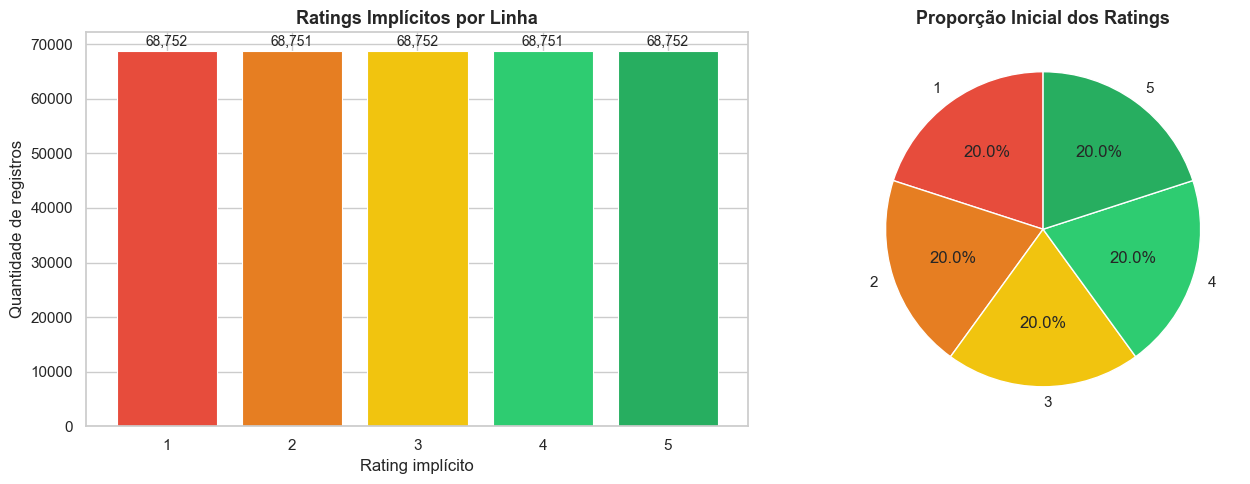

A distribuição inicial é uniforme por construção: os ratings são quintis do score implícito.


In [5]:
# Distribuição inicial dos ratings implícitos por linha
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

rating_counts = df['avaliacao'].value_counts().sort_index()

bars = axes[0].bar(rating_counts.index, rating_counts.values,
                   color=['#e74c3c','#e67e22','#f1c40f','#2ecc71','#27ae60'],
                   edgecolor='white', linewidth=0.8)
axes[0].set_title('Ratings Implícitos por Linha', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Rating implícito')
axes[0].set_ylabel('Quantidade de registros')
for bar, val in zip(bars, rating_counts.values):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 500,
                 f'{val:,}', ha='center', va='bottom', fontsize=10)

pct = rating_counts / rating_counts.sum() * 100
axes[1].pie(pct, labels=[f'{i}' for i in rating_counts.index],
            autopct='%1.1f%%', colors=['#e74c3c','#e67e22','#f1c40f','#2ecc71','#27ae60'],
            startangle=90)
axes[1].set_title('Proporção Inicial dos Ratings', fontsize=13, fontweight='bold')

plt.tight_layout()
plt.show()
print('A distribuição inicial é uniforme por construção: os ratings são quintis do score implícito.')


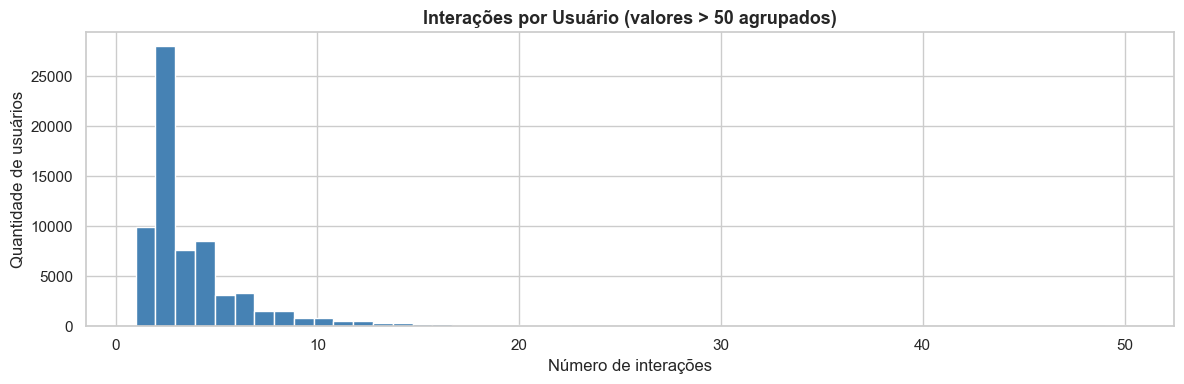

Usuário outlier       : ID 68564 com 79,505 interações
Mediana por usuário   : 2 interações
Usuários com 1 interação: 9,883


In [6]:
# Distribuição de interações por usuário
fig, ax = plt.subplots(figsize=(12, 4))
clipped = user_counts.clip(upper=50) # Limitar para visualização
ax.hist(clipped, bins=50, color='steelblue', edgecolor='white')
ax.set_title('Interações por Usuário (valores > 50 agrupados)', fontsize=13, fontweight='bold')
ax.set_xlabel('Número de interações')
ax.set_ylabel('Quantidade de usuários')
plt.tight_layout()
plt.show()

outlier_user = user_counts.idxmax()
print(f'Usuário outlier       : ID {outlier_user} com {user_counts.max():,} interações')
print(f'Mediana por usuário   : {user_counts.median():.0f} interações')
print(f'Usuários com 1 interação: {(user_counts == 1).sum():,}')

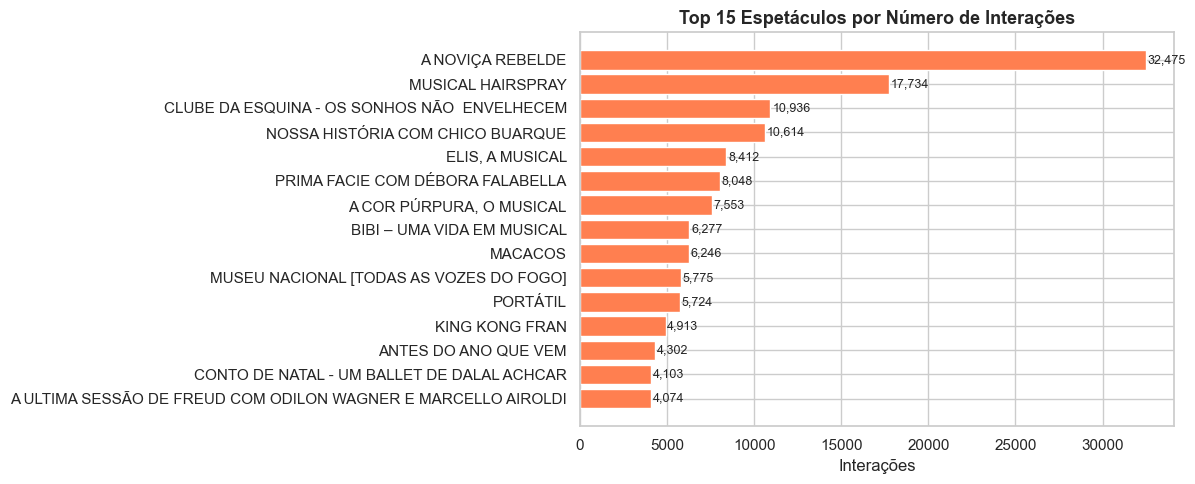

In [7]:
# Top 15 espetáculos mais avaliados
top_items = item_counts.sort_values(ascending=False).head(15)

fig, ax = plt.subplots(figsize=(12, 5))
bars = ax.barh(top_items.index[::-1], top_items.values[::-1], color='coral', edgecolor='white')
ax.set_title('Top 15 Espetáculos por Número de Interações', fontsize=13, fontweight='bold')
ax.set_xlabel('Interações')
for bar, val in zip(bars, top_items.values[::-1]):
    ax.text(bar.get_width() + 100, bar.get_y() + bar.get_height()/2,
            f'{val:,}', va='center', fontsize=9)
plt.tight_layout()
plt.show()

### 4.1 Etapas de Tratamento e Balanceamento

As etapas abaixo organizam o tratamento de dados até a base final do recomendador.

| Passo | Ação | Justificativa |
|---|---|---|
| 1 | Agregar duplicatas por par user-item | Consolida múltiplas compras/interações do mesmo usuário no mesmo espetáculo |
| 2 | Remover usuário outlier extremo | Usuários com volume anormal distorcem os padrões colaborativos |
| 3 | Filtrar cold-start de usuários | Usuários com menos de 3 interações não possuem histórico suficiente |
| 4 | Filtrar cold-start de itens | Itens com menos de 10 interações têm baixo suporte estatístico |
| 5 | Diagnosticar o score implícito contínuo | Verifica a distribuição real antes de transformar em classes ordinais |
| 6 | Converter score implícito em rating ordinal | Gera ratings 1-5 por quintis no nível user-item |
| 7 | Reavaliar necessidade de undersampling | Aplica redução amostral apenas se houver desbalanceamento relevante |


In [8]:
df = df.copy()

df_agg = (
    df.groupby(['id_user', 'nome_evento'], as_index=False)
      .agg(score_implicito=('score_implicito', 'mean'),
           interacoes_user_item=('interacoes_user_item', 'max'),
           antecedencia_dias=('antecedencia_dias', 'mean'),
           valor_medio=('valor_do_ingresso', lambda s: pd.to_numeric(s, errors='coerce').fillna(0).mean()),
           categoria=('categoria', 'first'),
           tipo_producao=('tipo_producao', 'first'),
           teatro=('teatro', 'first'))
)

print('Agregação por par usuário-item')
print(f'Registros antes : {len(df):>10,}')
print(f'Registros depois: {len(df_agg):>10,}')
print(f'Redução         : {len(df) - len(df_agg):>10,} registros')


Agregação por par usuário-item
Registros antes :    343,758
Registros depois:    112,347
Redução         :    231,411 registros


In [9]:
# Remover usuário outlier extremo
user_freq = df_agg.groupby('id_user').size()

# Remover usuários com mais de 500 interações (outlier extremo)
MAX_USER_INTERACTIONS = 500
valid_users = user_freq[user_freq <= MAX_USER_INTERACTIONS].index

df_agg = df_agg[df_agg['id_user'].isin(valid_users)]

removed = (~df_agg['id_user'].isin(valid_users)).sum()
print('Filtro de outliers de usuário')
print(f'Usuários removidos : {(user_freq > MAX_USER_INTERACTIONS).sum()}')
print(f'Registros restantes: {len(df_agg):>10,}')



Filtro de outliers de usuário
Usuários removidos : 1
Registros restantes:    111,790


In [10]:
# Filtrar cold start de usuários (mínimo 3 interações) 
MIN_USER_INTERACTIONS = 3

user_freq2 = df_agg.groupby('id_user').size()
valid_users2 = user_freq2[user_freq2 >= MIN_USER_INTERACTIONS].index
df_agg = df_agg[df_agg['id_user'].isin(valid_users2)]

print('Filtro de cold-start de usuários')
print(f'Usuários removidos : {(user_freq2 < MIN_USER_INTERACTIONS).sum():>10,}')
print(f'Registros restantes: {len(df_agg):>10,}')

Filtro de cold-start de usuários
Usuários removidos :     59,913
Registros restantes:     41,271


In [11]:
# Filtrar cold start de itens (mínimo 10 interações)
MIN_ITEM_INTERACTIONS = 10

item_freq = df_agg.groupby('nome_evento').size()
valid_items = item_freq[item_freq >= MIN_ITEM_INTERACTIONS].index
df_agg = df_agg[df_agg['nome_evento'].isin(valid_items)]

print('Filtro de cold-start de itens')
print(f'Itens removidos      : {(item_freq < MIN_ITEM_INTERACTIONS).sum():>10,}')
print(f'Registros restantes : {len(df_agg):>10,}')
print(f'Espetáculos restantes: {df_agg["nome_evento"].nunique():>10,}')

Filtro de cold-start de itens
Itens removidos      :         98
Registros restantes :     40,848
Espetáculos restantes:        343


### 4.2 Diagnóstico Estatístico Após Filtros

Depois da remoção de outliers e cold-start, o balanceamento é reavaliado no nível correto da matriz colaborativa: uma linha por par usuário-item. Antes de discretizar o score em ratings, analisamos o `score_implicito` contínuo para confirmar se os sinais comportamentais permanecem distribuídos de forma coerente.


Resumo do score implícito após filtros:
count    40848.0000
mean         0.3001
std          0.0786
min          0.0843
20%          0.2315
40%          0.2781
50%          0.2994
60%          0.3209
80%          0.3701
max          0.6058


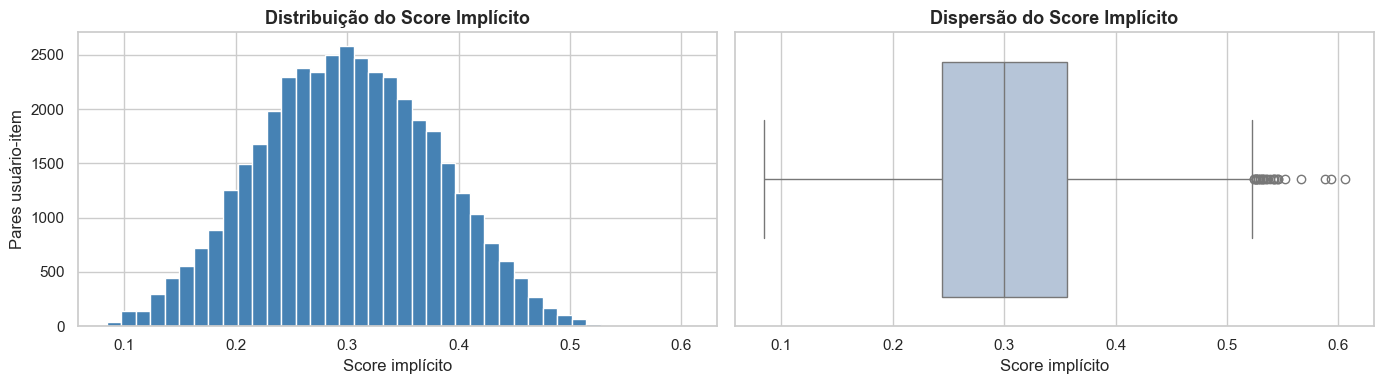

In [12]:
score_summary = df_agg['score_implicito'].describe(percentiles=[.2, .4, .6, .8]).round(4)
print('Resumo do score implícito após filtros:')
print(score_summary.to_string())

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].hist(df_agg['score_implicito'], bins=40, color='steelblue', edgecolor='white')
axes[0].set_title('Distribuição do Score Implícito', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Score implícito')
axes[0].set_ylabel('Pares usuário-item')

sns.boxplot(x=df_agg['score_implicito'], ax=axes[1], color='lightsteelblue')
axes[1].set_title('Dispersão do Score Implícito', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Score implícito')

plt.tight_layout()
plt.show()


In [13]:
# Converter score implícito agregado em rating ordinal e reavaliar balanceamento
# O rating é calculado após os filtros para representar a distribuição real usada pelo modelo.

def diagnosticar_distribuicao(series):
    counts = series.value_counts().sort_index()
    pct = (counts / counts.sum() * 100).round(2)
    resumo = pd.DataFrame({'registros': counts, 'percentual': pct})
    imbalance_ratio = counts.max() / counts.min()
    max_delta_pct = (counts.max() - counts.min()) / counts.sum() * 100
    return resumo, imbalance_ratio, max_delta_pct

df_agg['avaliacao'] = pd.qcut(
    df_agg['score_implicito'].rank(method='first'),
    q=5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

rating_summary, imbalance_ratio, max_delta_pct = diagnosticar_distribuicao(df_agg['avaliacao'])
needs_undersampling = imbalance_ratio > 2.0

print('Distribuição dos ratings após discretização por quintis')
print(rating_summary.to_string())
print(f'\nRazão maior/menor classe: {imbalance_ratio:.4f}')
print(f'Diferença máxima entre classes: {max_delta_pct:.4f}% do dataset')
print(f'Undersampling necessário? {"Sim" if needs_undersampling else "Não"}')

if needs_undersampling:
    target_size = rating_summary['registros'].min() * 2
    balanced_parts = []
    for rating_val, group in df_agg.groupby('avaliacao'):
        if len(group) > target_size:
            group = group.sample(n=target_size, random_state=42)
        balanced_parts.append(group)
    df_balanced = pd.concat(balanced_parts).sample(frac=1, random_state=42).reset_index(drop=True)
else:
    df_balanced = df_agg.sample(frac=1, random_state=42).reset_index(drop=True)

final_summary, final_ratio, final_delta_pct = diagnosticar_distribuicao(df_balanced['avaliacao'])
print('\nDistribuição final usada no pipeline:')
print(final_summary.to_string())
print(f'\nRazão final maior/menor classe: {final_ratio:.4f}')
print(f'Diferença final máxima entre classes: {final_delta_pct:.4f}% do dataset')


Distribuição dos ratings após discretização por quintis
           registros  percentual
avaliacao                       
1               8170        20.0
2               8169        20.0
3               8170        20.0
4               8169        20.0
5               8170        20.0

Razão maior/menor classe: 1.0001
Diferença máxima entre classes: 0.0024% do dataset
Undersampling necessário? Não

Distribuição final usada no pipeline:
           registros  percentual
avaliacao                       
1               8170        20.0
2               8169        20.0
3               8170        20.0
4               8169        20.0
5               8170        20.0

Razão final maior/menor classe: 1.0001
Diferença final máxima entre classes: 0.0024% do dataset


In [14]:
# Criar IDs numéricos para usuário e item
user_map = {u: i for i, u in enumerate(df_balanced['id_user'].unique())}
item_map = {e: i for i, e in enumerate(df_balanced['nome_evento'].unique())}

df_balanced['user_id'] = df_balanced['id_user'].map(user_map)
df_balanced['item_id'] = df_balanced['nome_evento'].map(item_map)
df_balanced['rating'] = df_balanced['avaliacao'].astype(float)

print('Dataset final para modelagem')
print(f'Usuários únicos   : {df_balanced["user_id"].nunique():>8,}')
print(f'Espetáculos únicos: {df_balanced["item_id"].nunique():>8,}')
print(f'Registros totais  : {len(df_balanced):>8,}')
df_balanced[['user_id','item_id','rating','score_implicito','nome_evento','categoria','tipo_producao']].head(10)


Dataset final para modelagem
Usuários únicos   :    8,648
Espetáculos únicos:      343
Registros totais  :   40,848


,user_id,item_id,rating,score_implicito,nome_evento,categoria,tipo_producao
0,0,0,2.0,0.252578,DETONAUTAS 20 ANOS - ACUSTICO,Show Musical,Nao informado
1,1,1,4.0,0.344074,RIO UPHILL - O MUSICAL,Espetáculo Musical,Nao informado
2,2,2,1.0,0.182819,JUNTEI TUDO PRA TE CONTAR - PAULO VIEIRA #TEAT...,Show Stand-Up,Nao informado
3,3,3,1.0,0.148258,SÍSIFO,Espetáculo Teatral,Nao informado
4,4,4,1.0,0.180219,"PEDRO MARIANO EM ""NOVO CAPÍTULO""",Show Musical,Nao informado
5,5,5,3.0,0.287315,BLACK BIRD - 25 ANOS,Show Musical,Nao informado
6,6,6,1.0,0.214774,NOEL ROSA: COISA NOSSA,Show Musical,Nao informado
7,7,7,3.0,0.283950,LOLOUCAS - COM HELOISA PÉRISSÉ E MARIA CLARA G...,Espetáculo Teatral,Nao informado
8,8,8,5.0,0.392309,"ELIS, A MUSICAL",Espetáculo Musical,Nao informado
9,9,9,2.0,0.271299,"A COR PÚRPURA, O MUSICAL",Espetáculo Musical,Nao informado


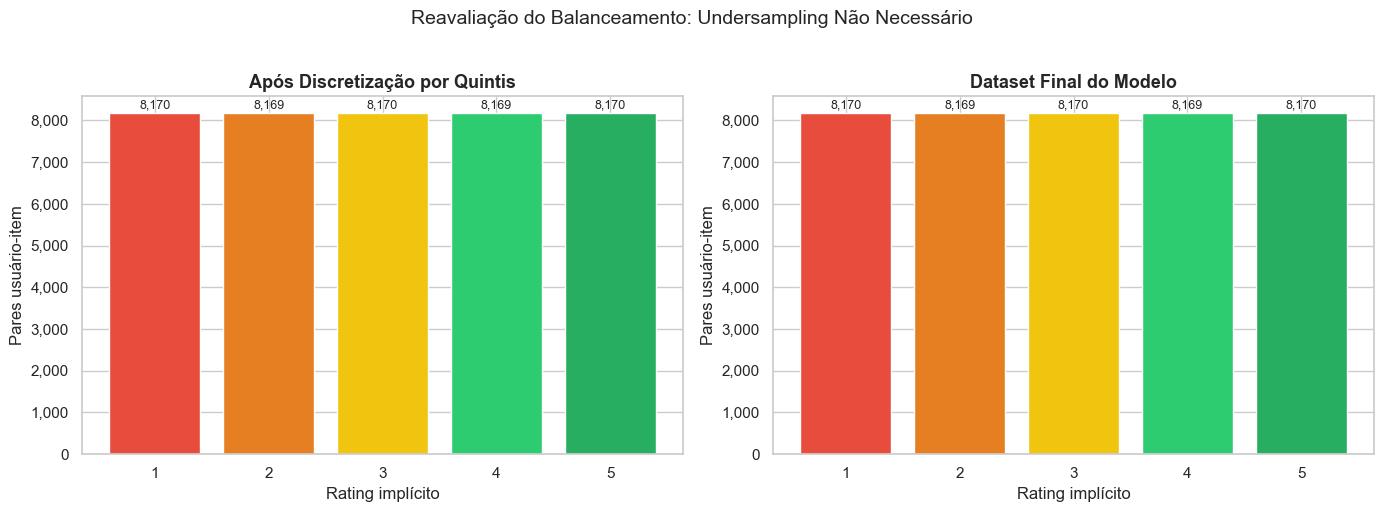

In [15]:
# Visualização comparativa da necessidade de balanceamento
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

colors = ['#e74c3c','#e67e22','#f1c40f','#2ecc71','#27ae60']

before = rating_summary['registros']
after = final_summary['registros']

axes[0].bar(before.index, before.values, color=colors, edgecolor='white')
axes[0].set_title('Após Discretização por Quintis', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Rating implícito')
axes[0].set_ylabel('Pares usuário-item')
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x):,}'))
for idx, val in before.items():
    axes[0].text(idx, val + 120, f'{val:,}', ha='center', fontsize=9)

axes[1].bar(after.index, after.values, color=colors, edgecolor='white')
axes[1].set_title('Dataset Final do Modelo', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Rating implícito')
axes[1].set_ylabel('Pares usuário-item')
axes[1].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x):,}'))
for idx, val in after.items():
    axes[1].text(idx, val + 120, f'{val:,}', ha='center', fontsize=9)

plt.suptitle('Reavaliação do Balanceamento: Undersampling Não Necessário', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()


Matriz usuário-item
Dimensões             : 8,648 x 343
Interações observadas : 40,848
Esparsidade           : 98.6229%


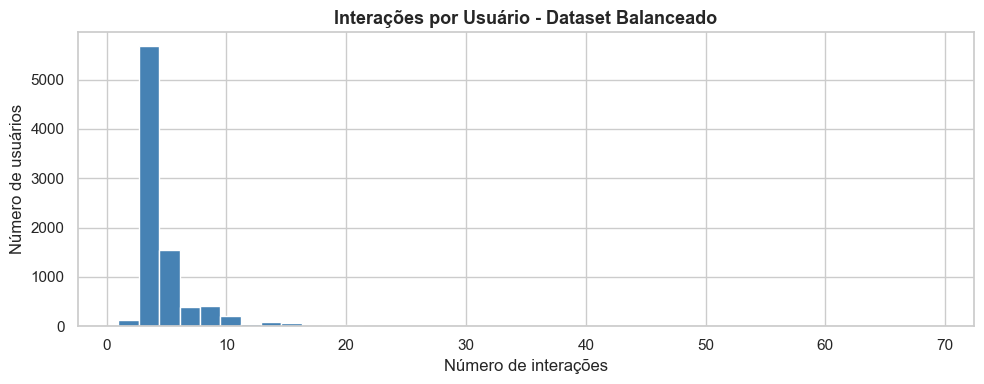

In [16]:
# Esparsidade da matriz user-item
n_users = df_balanced['user_id'].nunique()
n_items = df_balanced['item_id'].nunique()
n_interactions = len(df_balanced)
sparsity = 1 - (n_interactions / (n_users * n_items))

print('Matriz usuário-item')
print(f'Dimensões             : {n_users:,} x {n_items:,}')
print(f'Interações observadas : {n_interactions:,}')
print(f'Esparsidade           : {sparsity:.4%}')

# Distribuição final de interações por usuário
fig, ax = plt.subplots(figsize=(10, 4))
df_balanced.groupby('user_id').size().hist(bins=40, ax=ax, color='steelblue', edgecolor='white')
ax.set_title('Interações por Usuário - Dataset Balanceado', fontsize=13, fontweight='bold')
ax.set_xlabel('Número de interações')
ax.set_ylabel('Número de usuários')
plt.tight_layout()
plt.show()


In [17]:
# Salvar dataset final
# Arquivo principal para o modelo (Spotlight)
df_final = df_balanced[['user_id', 'item_id', 'rating', 'score_implicito']]
df_final.to_csv('../dataset/recomendacao_balanceado.csv', index=False)

# Arquivo auxiliar com metadados dos itens (útil para exibir nomes nas recomendações)
item_meta = (df_balanced[['item_id','nome_evento','categoria','tipo_producao']]
             .drop_duplicates('item_id')
             .sort_values('item_id'))
item_meta.to_csv('../dataset/itens_metadata.csv', index=False)

print('Arquivos finais salvos com sucesso')
print(f'recomendacao_balanceado.csv -> {len(df_final):,} registros')
print(f'itens_metadata.csv          -> {len(item_meta):,} espetáculos')
df_final.head()


Arquivos finais salvos com sucesso
recomendacao_balanceado.csv -> 40,848 registros
itens_metadata.csv          -> 343 espetáculos


,user_id,item_id,rating,score_implicito
0,0,0,2.0,0.252578
1,1,1,4.0,0.344074
2,2,2,1.0,0.182819
3,3,3,1.0,0.148258
4,4,4,1.0,0.180219


## 5. Conclusão

A preparação da base consolidou um dataset transacional em uma estrutura adequada para recomendação por filtragem colaborativa. O principal ajuste metodológico foi substituir avaliações artificiais por um feedback implícito calculado a partir de sinais reais de comportamento dos usuários.

### Principais Resultados

1. **Ratings sintéticos removidos**: a geração probabilística de avaliações foi eliminada. No lugar dela, cada interação passou a receber um `score_implicito` calculado com base em três sinais observáveis da própria base: recorrência do par usuário-evento, valor do ingresso e antecedência da compra.

2. **Conversão do score em rating ordinal**: após a agregação por par usuário-item, o `score_implicito` contínuo foi convertido em ratings de 1 a 5 por quintis. Essa escolha transforma o comportamento real em uma escala compatível com modelos de filtragem colaborativa baseados em rating, sem usar notas aleatórias ou probabilidades definidas artificialmente.

3. **Interpretação dos ratings**: o rating final deve ser lido como uma medida relativa de intensidade de interesse. Um rating 5 representa interações com maior força relativa dentro da base tratada, enquanto um rating 1 representa menor intensidade relativa. Portanto, os valores não indicam satisfação explícita declarada pelo usuário, mas sim uma ordenação comportamental derivada dos dados disponíveis.

4. **Duplicatas consolidadas**: múltiplos registros do mesmo par usuário-evento foram agregados em uma única interação, preservando o score implícito médio e a recorrência observada.

5. **Outlier crítico tratado**: o usuário de ID `68564`, responsável por 79.505 registros, foi removido por apresentar volume incompatível com comportamento regular de uso.

6. **Cold-start reduzido**: usuários com menos de 3 interações e itens com menos de 10 interações foram filtrados para manter histórico mínimo na matriz colaborativa.

7. **Balanceamento validado**: a distribuição final dos ratings ficou praticamente uniforme porque a escala ordinal foi criada por quintis do score contínuo. Essa uniformidade não vem de sorteio ou simulação; ela é consequência da estratégia de discretização adotada e validada para manter classes comparáveis no treinamento. Como a razão maior/menor classe foi de aproximadamente 1,0001, não houve necessidade de undersampling adicional.

### Dataset Final

| Métrica | Valor |
|---|---|
| Total de registros brutos | 343.758 |
| Usuários únicos brutos | 68.564 |
| Eventos únicos brutos | 571 |
| Registros após agregação, filtros e revisão de balanceamento | 40.848 |
| Usuários no dataset final | 8.648 |
| Eventos no dataset final | 343 |
| Esparsidade da matriz usuário-item | 98,6229% |

### Próximos Passos

1. Validar com o grupo os pesos usados no score implícito;
2. Criar split treino/teste reprodutível e sem vazamento de interações;
3. Implementar um baseline simples para comparação;
4. Treinar e avaliar modelos colaborativos compatíveis com ratings ordinais;
5. Medir métricas de erro e ranking, como RMSE, MAE, Precision@K e Recall@K;
6. Preparar a integração das recomendações com o Portal Aventura.


## 6. Sequenciamento e Priorização das Próximas Entregas

Com o dataset reorganizado, o feedback implícito definido e o balanceamento revisado, as próximas entregas devem seguir uma ordem que reduza risco técnico e mantenha rastreabilidade entre dados, modelo e integração com o produto.

### 6.1 Backlog Técnico Priorizado

| Prioridade | Entrega | Objetivo | Critério de conclusão | Dependências |
|---|---|---|---|---|
| P0 | Validar pesos do score implícito | Confirmar se recorrência, valor do ingresso e antecedência representam adequadamente interesse do usuário | Pesos aprovados ou ajustados e documentados no notebook | Dataset tratado e análise de balanceamento |
| P0 | Gerar split treino/teste | Criar separação reprodutível para avaliação offline do recomendador | Arquivos ou variáveis de treino/teste criados com `random_state` definido | Dataset final `recomendacao_balanceado.csv` |
| P0 | Definir baseline de recomendação | Estabelecer referência mínima para comparação dos modelos | Baseline simples implementado e medido, como popularidade ou média por item | Split treino/teste |
| P1 | Treinar primeiro modelo colaborativo | Testar algoritmo compatível com ratings ordinais e matriz esparsa | Modelo treinado com métricas offline registradas | Baseline e split treino/teste |
| P1 | Avaliar métricas de recomendação | Medir qualidade com métricas de erro e ranking | RMSE/MAE e Precision@K ou Recall@K reportados | Modelo colaborativo treinado |
| P1 | Mapear recomendações para metadados | Converter `item_id` recomendado em nome, categoria e tipo de produção | Saída interpretável usando `itens_metadata.csv` | Modelo treinado e metadados versionados |
| P2 | Prototipar endpoint de recomendação | Disponibilizar recomendações para consumo pelo portal | Endpoint ou função de serviço retornando recomendações por usuário | Modelo validado e mapeamento de metadados |
| P2 | Documentar limitações e riscos | Registrar restrições do feedback implícito e hipóteses de negócio | Seção metodológica atualizada com riscos e decisões | Resultados das avaliações offline |

### 6.2 Dependências Técnicas

| Dependência | Impacto no sequenciamento | Como mitigar |
|---|---|---|
| Validação dos pesos do score implícito | Pode alterar ratings e exigir nova execução do pipeline | Manter cálculo parametrizado e documentado |
| Qualidade do split treino/teste | Afeta a confiabilidade das métricas do modelo | Usar separação reprodutível e evitar vazamento de interações |
| Esparsidade da matriz user-item | Pode reduzir desempenho de algoritmos colaborativos | Comparar baseline, modelos de fatoração e filtros de cold-start |
| Metadados dos itens | Necessários para transformar recomendações em saída compreensível | Versionar `itens_metadata.csv` junto com o dataset final |
| Integração com o portal | Depende de formato de resposta estável | Definir contrato mínimo da recomendação antes do endpoint |

### 6.3 Cronograma Resumido

| Etapa | Entregas previstas | Resultado esperado |
|---|---|---|
| Sprint 1 | Validar pesos do score implícito, gerar split treino/teste e implementar baseline | Métrica inicial de referência para recomendação |
| Sprint 2 | Treinar modelo colaborativo, comparar métricas e selecionar abordagem candidata | Modelo candidato documentado e comparado ao baseline |
| Sprint 3 | Mapear recomendações para metadados, preparar interface de consumo e documentar limitações | Saída de recomendação interpretável e pronta para integração |
| Sprint 4 | Prototipar endpoint, validar com o grupo e ajustar pesos/modelo se necessário | Pipeline de recomendação validado para evolução do produto |

### 6.4 Ordem Recomendada de Execução

1. Validar com o grupo a regra de score implícito e seus pesos;
2. Reexecutar o pipeline caso os pesos sejam alterados;
3. Criar split treino/teste reprodutível;
4. Implementar baseline simples para comparação;
5. Treinar modelo colaborativo inicial;
6. Avaliar métricas offline e comparar com o baseline;
7. Mapear recomendações para metadados interpretáveis;
8. Preparar protótipo de integração com o portal.

Essa sequência prioriza primeiro a confiabilidade dos dados e da avaliação, depois a modelagem e, por fim, a integração. Assim, cada entrega depende de uma base metodológica validada antes de avançar para decisões de produto.
